In [11]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [12]:
# Reading MNIST data from CSV file with function from Panada library 
df = pd.read_csv('mnist_784.csv')
X = df.iloc[:,0:784].values/255
Y0 = df.iloc[:,784].values

print(Y0[1])


# one hot conversion
Y=np.zeros((70000,10)) 
for i in range(70000): 
    Y[i,Y0[i]]=1

# devide into 60000 training example and 100000 test examples
x_train = X[:60000,:].T
x_test = X[60000:,:].T
y_train = Y[:60000,:].T
y_test = Y[60000:,:].T

print(x_train.shape, y_train.shape)
print(x_test.shape, y_test.shape)

0
(784, 60000) (10, 60000)
(784, 10000) (10, 10000)


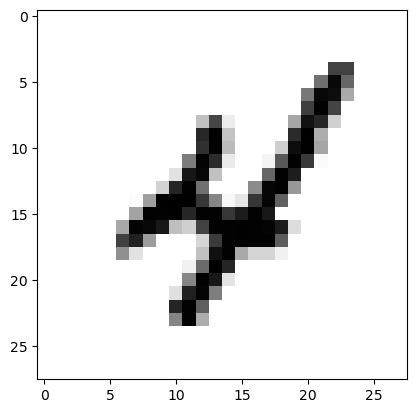

In [13]:
# Example of printing picture of an example input 
img=X.reshape(70000,28,28)
plt.imshow(img[9], cmap='binary')

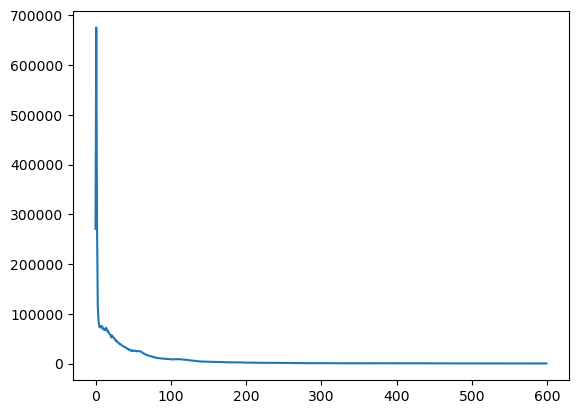

In [14]:
# model specifications
Ni=784; Nh=128; No=10

#parameter and array initialization
Nepochs=10
wh=np.random.randn(Nh,Ni)  
wo=np.random.randn(No,Nh) 
error=np.array([])

for epoch in range(Nepochs):
    # using minibatches of size 1000 
    for batch in range(60):
        Xtrain=x_train[:,batch*1000:(batch+1)*1000]
        Ytrain=y_train[:,batch*1000:(batch+1)*1000]

        # Calculate hidden nodes activation
        h=1/(1+np.exp(-wh@Xtrain))
        # Calculate output nodes activation 
        y=wo@h
        
        # update of output node with square loss function loss=1/2*(y-Ytrain)**2 
        do=y-Ytrain
        wo=wo-0.0001*do@h.T

        # update of hidden weights with error backpropagation  
        dh=wo.T@do 
        wh=wh+0.0001*h*(1-h)*dh@Xtrain.T   
        
        error=np.append(error,np.sum(0.5*(Ytrain-y)**2))
plt.plot(error)

In [15]:
# Check the predictions on the test set
h=1/(1+np.exp(-wh@x_test))
y=wo@h
y=np.argmax(y,axis=0)
y1=np.argmax(y_test,axis=0)
ncorrect=np.sum((y1==y))
print('number of correct pattern out of 10000: ',ncorrect)


number of correct pattern out of 10000:  7780
